# 01: EDA and data audit (HKUST primary data)

This notebook is built up task by task (Stage 1 in `PLAN.md`). Reusable code is in `src/`; the cells here stay short and simple.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
from src import inventory

## 2. Station inventory

One row per site-level power file. File facts (resolution, dates, rows) come from the CSVs. Rated power, tilt, azimuth and location come from the `.ttl` metadata, matched by station name (all 60 match; one name, *Indoor Sports Centre*, needed a manual fix).

In [2]:
inv = inventory.build_inventory()
inv.shape

(60, 18)

In [3]:
inv.head()

,station,has_optimizer,resolution_min,start,end,n_rows,n_duplicate_timestamps,n_inverter_files,ttl_name,latitude,longitude,altitude_m,connection_date,rated_unit,rated_value,azimuth_raw,tilt_raw,contractor
0,Indoor Sports Centre,True,15.0,2021-12-02,2023-12-31 23:45:00,72960,0,1,Indoor_Sport_Center,22.28,114.17,3.0,2021-12-01T00:00:00,KW,33.3,0/180deg,10deg,SolarEdge
1,LSK North,True,15.0,2021-06-01,2023-12-31 23:45:00,90624,0,1,LSK_North,22.33,114.18,142.0,2021-04-30T00:00:00,KW,55.0,10/-153deg,10deg,SolarEdge
2,LSK South,True,15.0,2021-06-01,2023-12-31 23:45:00,90624,0,1,LSK_South,22.33,114.18,152.0,2021-04-30T00:00:00,KW,25.0,0deg,0deg,SolarEdge
3,Library,True,15.0,2022-06-01,2023-12-31 23:45:00,55584,0,3,Library,22.28,114.17,87.0,2022-05-31 00:00:00,KW,170.2,Mixed,10deg,SolarEdge
4,S H Ho Sports Hall,True,15.0,2021-11-01,2023-12-31 23:45:00,75936,0,2,S_H_Ho_Sports_Hall,22.28,114.17,96.0,2021-10-02 00:00:00,KW,42.0,0deg,0deg,SolarEdge


### Checks on the join

In [4]:
print('files without .ttl match:', inv['ttl_name'].isna().sum())
print('rated power units:', inv['rated_unit'].unique())
print('inverter files:', inv['n_inverter_files'].sum())

files without .ttl match: 0
rated power units: <StringArray>
['KW']
Length: 1, dtype: str
inverter files: 44


In [5]:
inv.groupby('has_optimizer')[['resolution_min']].agg(['count', 'min', 'max'])

resolution_min            
                       count   min   max
has_optimizer                           
False                     23  60.0  60.0
True                      37  15.0  15.0

### Stations with problems to note

In [6]:
inv[inv['n_duplicate_timestamps'] > 0][['station', 'n_rows', 'n_duplicate_timestamps']]

,station,n_rows,n_duplicate_timestamps
39,SQ Apartment37-48 Flexible PV,21088,432
46,SQ14,24429,586
58,Zone L1 (Station 1),33958,10099
59,Zone L1(Station 2),25929,2074


In [7]:
inv[inv['start'] >= '2023-01-01'][['station', 'has_optimizer', 'start']]

,station,has_optimizer,start
9,SQ Block P,True,2023-07-01
17,Shaw Auditorium,True,2023-08-01
24,UG Hall8,True,2023-03-02
25,UG Hall9,True,2023-02-11


In [8]:
inv[inv['end'] >= '2024-01-01'][['station', 'end']]

,station,end
58,Zone L1 (Station 1),2024-01-01 03:00:00


### Save the table

In [9]:
inv.to_csv('../results/tables/01_station_inventory.csv', index=False)

## 3. Units and timezone

### 3.1 Power (W) vs generation (kWh)

If `power(W)` is a mean over the step, then `generation(kWh)` should equal power x step length / 1000. We test that for both station types.

In [10]:
from src import data_io
files = data_io.list_station_files()
hourly = files[~files['has_optimizer']]
quarter = files[files['has_optimizer']]

**Hourly stations (23):** share of rows where kWh x 1000 equals W (within 1 W), among rows that are not missing.

In [11]:
shares = []
for path in hourly['path']:
    x = data_io.read_station_power(path).dropna()
    diff = (x['generation(kWh)'] * 1000 - x['power(W)']).abs()
    shares.append((diff <= 1).mean())

print('lowest share of matching rows:', min(shares))

lowest share of matching rows: 1.0


**15-min stations (37):** total kWh divided by (sum of W x 0.25 h / 1000). A value of 1.00 would mean exact agreement.

In [12]:
ratios = []
for path in quarter['path']:
    x = data_io.read_station_power(path)
    x = x[~x.index.duplicated()]
    expected = x['power(W)'].sum() * 0.25 / 1000
    ratios.append(x['generation(kWh)'].sum() / expected)

print('min:', round(min(ratios), 3), ' max:', round(max(ratios), 3))

min: 1.028  max: 1.033


### 3.2 Irradiance (W/m2)

In [13]:
irr = data_io.read_weather('irradiance')['Irradiance (W/m2)']
irr.describe().round(1)

count    1567792.0
mean         150.6
std          253.5
min            0.0
25%            4.9
50%           23.7
75%          177.9
max         3608.6
Name: Irradiance (W/m2), dtype: float64

In [14]:
print('values above 1500 W/m2:', (irr > 1500).sum(), 'of', len(irr))
night = irr[irr.index.hour <= 4]
print('night (00-04h) median:', round(night.median(), 1), ' 95th percentile:', round(night.quantile(0.95), 1))

values above 1500 W/m2: 739 of 1567792
night (00-04h) median: 5.4  95th percentile: 31.8


### 3.3 Timezone

The timestamps carry no timezone. If they are Hong Kong local time (UTC+8), irradiance should peak near solar noon. At longitude 114.17 E solar noon is about 12:23 on the clock (12 h + (120 - 114.17) / 15 h), moving by up to about 15 min over the year (equation of time). If the clock were UTC, the peak would be near 04:20.

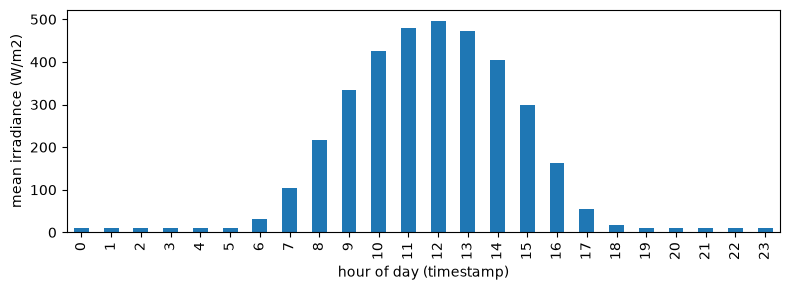

In [15]:
import matplotlib.pyplot as plt

mean_by_hour = irr.groupby(irr.index.hour).mean()
mean_by_hour.plot(kind='bar', figsize=(8, 3))
plt.xlabel('hour of day (timestamp)')
plt.ylabel('mean irradiance (W/m2)')
plt.tight_layout()
plt.savefig('../results/figures/01_irradiance_by_hour.png', dpi=120)
plt.show()

Daily centre of mass of irradiance (hour of day), median per month, on days with almost no missing minutes:

In [16]:
clock_hour = irr.index.hour + irr.index.minute / 60
day = irr.index.normalize()
table = pd.DataFrame({'irr': irr.values, 'weighted': irr.values * clock_hour, 'day': day})
daily = table.groupby('day').agg(total=('irr', 'sum'), weighted=('weighted', 'sum'), minutes=('irr', 'size'))
daily = daily[daily['minutes'] >= 1400]
daily['centre_hour'] = daily['weighted'] / daily['total']
daily.groupby(daily.index.month)['centre_hour'].median().round(2)

day
1     12.42
2     12.55
3     12.55
4     12.29
5     12.21
6     12.10
7     12.14
8     12.13
9     12.17
10    12.06
11    12.02
12    12.14
Name: centre_hour, dtype: float64

### Findings

- **Hourly stations:** `generation(kWh)` x 1000 equals `power(W)` wherever values exist (the other rows are missing values), so `power` is the mean power over the hour and `generation` is the energy of that hour.
- **15-min stations:** `generation(kWh)` summed over a station is 2.8-3.3 % above `power(W)` x 0.25 h / 1000, and the per-row ratio varies (5th-95th percentile about 0.21-0.32 instead of 0.25). So `power(W)` is close to, but not exactly, the mean power of the 15-min step. Which one is the model target is decided in Stage 2; power in W is the planned target.
- **Irradiance** is in W/m2 and never negative. A few values exceed 1500 W/m2 (max 3608, outliers). There is a small non-zero night level (median about 5 W/m2), which is a sensor offset to handle in preprocessing.
- **Timezone:** the irradiance centre of mass is between about 12.0 and 12.6 h in every month, close to the expected solar noon (about 12.1-12.6 h through the year). The timestamps are therefore local Hong Kong time (UTC+8, no daylight saving). A summer dip of up to about 20 min is plausible from afternoon clouds; we did not investigate it.

## 4. Timestamp convention and alignment

Question: does a timestamp label the **start** or the **end** of its interval (15 min or 1 h)?

Method: irradiance is measured every minute. For a station value at time `t`, we take the mean irradiance over a window of the same length (15 or 60 min) that ends at `t + k` minutes, and compute the correlation with the station power. The best `k` shows which part of time the value really describes:

- window ends at `t` (`k = 0`): the value covers the interval **before** `t` (label = interval end)
- window ends at `t + 15` for 15-min data (`k = 15`): the value covers the interval **after** `t` (label = interval start)

Only daytime rows are used (mean irradiance above 50 W/m2).

### 4.1 Setup: irradiance on a full 1-minute grid

In [17]:
irr = data_io.read_weather('irradiance')['Irradiance (W/m2)']
irr = irr[~irr.index.duplicated()]
minute_grid = pd.date_range('2021-01-01', '2023-12-31 23:59', freq='1min')
irr = irr.reindex(minute_grid)
print('missing minutes:', irr.isna().sum())
print('weather timestamps with seconds:', (irr.dropna().index.second != 0).sum())

missing minutes: 9008
weather timestamps with seconds: 0


In [18]:
mean15 = irr.rolling(15, min_periods=15).mean()
mean60 = irr.rolling(60, min_periods=60).mean()

### 4.2 Do the timestamps sit on the same grid?

In [19]:
minutes_15 = []
for path in quarter['path']:
    x = data_io.read_station_power(path)
    minutes_15.append(set(x.index.minute))
print('minute values in 15-min files:', sorted(set.union(*minutes_15)))

minutes_60 = []
for path in hourly['path']:
    x = data_io.read_station_power(path)
    minutes_60.append(set(x.index.minute))
print('minute values in hourly files:', sorted(set.union(*minutes_60)))

minute values in 15-min files: [0, 15, 30, 45]


minute values in hourly files: [0]


### 4.3 Helper and rated power (used to drop impossible power values)

In [20]:
def corr_at_shift(series, window_mean, k):
    shifted = window_mean.shift(-k).reindex(series.index)
    ok = series.notna() & shifted.notna() & (shifted > 50)
    return series[ok].corr(shifted[ok])

rated = pd.read_csv('../results/tables/01_station_inventory.csv').set_index('station')['rated_value']

### 4.4 15-min stations (37): power and generation

In [21]:
shifts_15 = list(range(0, 31, 3))
rows_power = []
rows_gen = []
for name, path in zip(quarter['station'], quarter['path']):
    x = data_io.read_station_power(path)
    x = x[~x.index.duplicated()]
    power = x['power(W)'].clip(lower=0, upper=1.2 * rated[name] * 1000)
    gen = x['generation(kWh)'].clip(lower=0)
    rows_power.append([corr_at_shift(power, mean15, k) for k in shifts_15])
    rows_gen.append([corr_at_shift(gen, mean15, k) for k in shifts_15])

In [22]:
power_15 = pd.DataFrame(rows_power, columns=shifts_15)
gen_15 = pd.DataFrame(rows_gen, columns=shifts_15)
table_15 = pd.DataFrame({'power_W': power_15.mean(), 'generation_kWh': gen_15.mean()}).round(4)
table_15.index.name = 'k_minutes'
table_15

,power_W,generation_kWh
k_minutes,,
0,0.8090,0.8271
3,0.8195,0.8378
6,0.8303,0.8476
9,0.8404,0.8555
12,0.8479,0.8593
15,0.8510,0.8583
18,0.8485,0.8523
21,0.8421,0.8436
24,0.8332,0.8335


In [23]:
print('best k per station (power):')
print(power_15.idxmax(axis=1).value_counts().sort_index())

best k per station (power):
12     8
15    19
18    10
Name: count, dtype: int64


### 4.5 Hourly stations (23)

In [24]:
shifts_60 = list(range(-60, 31, 10))
rows_hour = []
for name, path in zip(hourly['station'], hourly['path']):
    x = data_io.read_station_power(path)
    x = x[~x.index.duplicated()]
    power = x['power(W)'].clip(lower=0, upper=1.2 * rated[name] * 1000)
    rows_hour.append([corr_at_shift(power, mean60, k) for k in shifts_60])

In [25]:
power_60 = pd.DataFrame(rows_hour, columns=shifts_60)
table_60 = power_60.mean().round(4).rename('power_W').to_frame()
table_60.index.name = 'k_minutes'
table_60

,power_W
k_minutes,
-60,0.7283
-50,0.7606
-40,0.7893
-30,0.8133
-20,0.8316
-10,0.8432
0,0.8450
10,0.8350
20,0.8159


In [26]:
print('best k per station:')
print(power_60.idxmax(axis=1).value_counts().sort_index())

best k per station:
-10    10
 0     11
 10     1
 20     1
Name: count, dtype: int64


### 4.6 Is it the same in every year? (15-min stations, power)

In [27]:
shifts_year = [0, 9, 15, 21]
result_year = {}
for year in [2021, 2022, 2023]:
    rows = []
    for name, path in zip(quarter['station'], quarter['path']):
        x = data_io.read_station_power(path)
        x = x[~x.index.duplicated()]
        power = x['power(W)'].clip(lower=0, upper=1.2 * rated[name] * 1000)
        power = power[power.index.year == year]
        rows.append([corr_at_shift(power, mean15, k) for k in shifts_year])
    result_year[year] = pd.DataFrame(rows, columns=shifts_year).mean()
pd.DataFrame(result_year).round(4)

,2021,2022,2023
0,0.8484,0.8817,0.8756
9,0.8890,0.9134,0.9078
15,0.9029,0.9226,0.9192
21,0.8917,0.9138,0.9098


### 4.7 Save the table and a figure

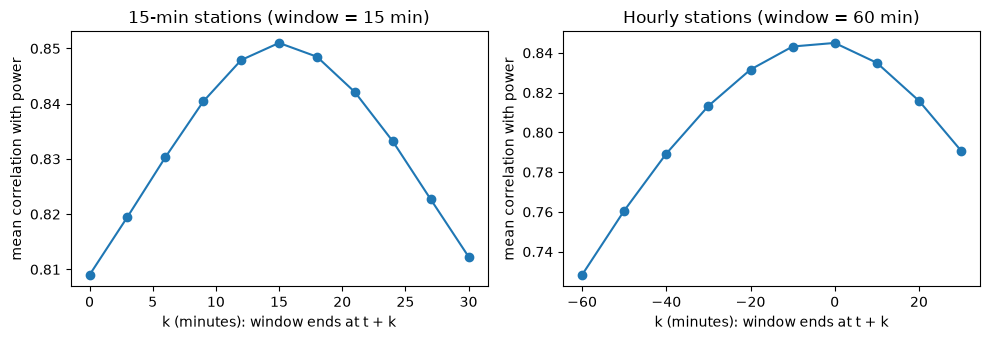

In [28]:
table_15.to_csv('../results/tables/01_timestamp_alignment_15min.csv')
table_60.to_csv('../results/tables/01_timestamp_alignment_hourly.csv')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
table_15['power_W'].plot(ax=axes[0], marker='o')
axes[0].set_title('15-min stations (window = 15 min)')
table_60['power_W'].plot(ax=axes[1], marker='o')
axes[1].set_title('Hourly stations (window = 60 min)')
for ax in axes:
    ax.set_xlabel('k (minutes): window ends at t + k')
    ax.set_ylabel('mean correlation with power')
plt.tight_layout()
plt.savefig('../results/figures/01_timestamp_alignment.png', dpi=120)
plt.show()

### Findings: timestamp convention

- **Grid:** weather timestamps are whole minutes; 15-min power files use :00/:15/:30/:45 and hourly files use :00, so all series sit on the same minute grid (no offsets in seconds).
- **15-min optimizer stations:** the correlation peaks at `k = 12-18` (pooled peak at `k = 15`; the same for 2021, 2022 and 2023, and for both `power(W)` and `generation(kWh)`). A value labelled `t` therefore describes the interval **after** `t`, i.e. `[t, t + 15 min)`: the label is the interval **start**.
- **Hourly stations:** the correlation peaks at `k` between -10 and 0 (22 of 23 stations at -10 or 0). A value labelled `t` describes the hour **before** `t`, i.e. `[t - 60 min, t)`: the label is the interval **end**. So the two station types use **different conventions**.
- **Consequence for leakage (Stage 2):** a 15-min row labelled `t` contains information up to `t + 15 min`, so it is only known at `t + 15 min`. An hourly row labelled `t` is known at `t`. Feature construction and the forecast issue time must use this, otherwise the models see the future.
- **Limits:** the result is relative to the weather timestamps (we assume the 1-min irradiance is labelled at the minute it is measured; an error of about 1 min would not change the result). The correlation peak is broad, so the offset is known to about +-3 min, not exactly. The answer is based on correlation with irradiance, not on a statement in the dataset documentation, which we did not find.